In [1]:
from IPython.core.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

# Assignment 2 - Gradient Boosting meets NZ Inflation



### Student Name: John Balint Lavack
### Student ID: 20001249

YOU NEED TO EXPLAIN AND DISCUSS BELOW WHAT TASKS YOU MANAGED TO COMPLETE AND HOW YOU COMPLETED THEM WHERE NECESSARY



## [Task 1: Gradient Boosting Implementation (25 Marks)](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION)

1. [Implement Gradient Boosting Algorithm: (5 marks)](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION)
   - I managed to properly implement the simplified Gradient Boosting algorithm from class code and have demonstrated that it works by using it to fit and predict the data set on traffic usage and GDP from class. Shown by pairwise residual plots of the data, the residual fit plots, convergence plots and prediction fit plots showing the true y and the model predictions. In this question's answer I also show the fits in similar ways for different loss functions. 
   
   <a href="#TASK-1" >GB class implementation</a>
  

2. [Adjust the Loss Function: (5 marks)](#Task-1.2-Adjust-the-Loss-Function)
   - I adjusted the loss function by implementing at least TWO different types which were:
   1. Friedman MSE
   2. Mean Absolute Error
   3. Huber loss
   4. Smoothed Quantile loss
   <a href="#TASK-1" >GB loss fucntion</a>
   
   - The effects vary by loss function. I viewed the loss function compared to the evaluation metric appropriate for the loss funciton. 
       1. MSE loss converges with the MSE score relatively fast. Around 10 iterations or so. With the data set used there is a suggested asymptote around 3.7 or so for both. 
       2. Friedman MSE quickly descends from on high to converge quickly around the same number as regular MSE. Albeit somewhat faster in terms of model fitting. Friedman MSE is a tad more efficient and can get to the MSE score faster, in principle, for more iterations. In my tests it dodn't work out that way over 20 iterations, but in later fits during Task 2 it did compute faster.
       3. MAE had lower initial loss and convereged quickly to 1. Seemingly asymptotic at 1. The MAE score and the MAE loss converged. MAE, perhaps because it is robust to outliers, is more stable and so looks to take longer for loss and score to converge. 
       4. Huber loss increased as the huber scoring metric decreases. They appear to need many more iterations. Being robust to outliers and piecewise about the $\gamma$ means that one can configure that $\gamma$ to perhaps find better convergence. 
       5. Quantile loss was linear. Doing poorly, neither loss nor score converging.        
   

3. [Adjust Weak Learner Type: (5 marks)](#Task-1.3-Adjust-Weak-Learner-Type)
   - I conducted an experiment with two different weak learner types within the Gradient Boosting ensemble
   - They were:
       1. [Decision Tree of adjustable depth](#1.3.1-Decision-Tree:) 
       2. [Multi Layered Perceptrons](#1.3.2-Multi-Layered-Perception-(Neural-Network):)
       3. [Xtreme Gradient boost](#1.3.3-XGBOOST:) as a bonus which I implemented out of curiosity. 
       
       
   - As a result of doing the above, I found:
       1. For decision trees, deeper trees performed very poorly. While shallower trees did better. Stump being the best. Just like with AdaBoost, more complex models result in poorer fits in the ensemble. They become 'expoert' learners. Or so it appears. Ith deep trees of 20 getting horendous fits and MSEs in the thousands. 
       2. MLP: having lots of customisability, it cna be tuned to fit better or worse. Hidden layers and epochs impactingt his the most. Again, making the model too 'clever' makes it fit worse. 
       3. Xtreme bonus: On the data set used, the XGBoost was worse than gradient boosting. It is faster to compute because the hessian is easier to work with. Mostly 1s or 0s usually. However, perhaps because of the data itself, the model was poor fitting

4. [Modify the Learning Rate Schedule: (5 marks)](#Task-1.4-Modify-the-Learning-Rate-Schedule)
   - I devised and implemented a dynamic learning rate schedule where the learning rate decreases as the number of iterations increases and found that this can be true in some cases. Usually a higher learning rate to start with, decaying to a floor does result in better fitting and faster converging models. Though this is not a given, nor can it be expected. I varies much by decay functions. 
   
   - I explored different schedules and provided a set of experiments as well as a discussion to report on my findings which were extensive. I went gang busters and implemented many decay functions. The shape of the decay function matters. This can be seen by viewing the eta history of the model. This is really a case of knowing the right tool for the job, although I did devise a novel decay function that works pretty well regardless of what one knows in advance. I'd like to call it 'PuntBoost' as in 'to take a punt' but it is perhaps more accurately called 'Adaptive Boost'.  
   
   - The trade-offs between starting with a higher learning rate versus a more conservative fixed learning rate in my experiments were primarily computational. YOu can learn faster and stop sooner if you use an aggressive decay function. Someimtes that model will stabilise it's scoring metric quickly, but this is not always a good thing. In some cases, like exponential decay or gradient decay, the model converges, but to a poor value. Meaning it may be better to more gradually decay the model from a starting point nearer the initial learning rate. Neither being too conservative nor too gung ho. 
   
5. [Implement Gradient-Based Early Stopping : (5 marks)](#Task-1.5-Early-Stopping:)
   - I managed to implement an early stopping mechanism by doing an orthodox approach of having a validation sub sample, tolerance and patience values. Wherein the model stops fitting once the loss funciton ceases to improve better than the tolerance of a period of iterations equal to the patience. Once the model stops, you then need to fit it again with the specified number of rounds, other wise the model trained and fit on less data than the full training set. 
      
   - My strategy resulted in early stopping, but the MSE was worse. around 4.04 to 3.85, and 3.9 to 3.85 when tuning the early stopping. Early stopping effectively means that we make a trade off decision on bias vs variance. It is not inherently good or bad. In fact, it is incredibly useful for Grid Search. However, what I found was that on the data I used, it was not much better than not having it. 
   
   - Since the whole point of early stopping is for regularisation, I decided to implement drop out (DARTS) and subsampling. These worked better than early stopping because they use randomness to force the model to fit differently each boosting round. Drop out was very good as shown in the fitting in task 2. 
   
   
## [Task 2: Gradient Boosting In-Class NZ Inflation Forecasting Competition (35 Marks)](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION)


1. Competition Score Calculation: (20 marks)
   - I can confirm that I read the competition rules and I followed them completely.
   - I used the following datasets and original raw features from the following sources:
       * [MBIE Coal statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/coal-statistics)
       * [MBIE Oil statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/oil-statistics)
       * [MBIE Renewables statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/gas-statistics)
       * [MBIE Electricity statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/renewables-statistics)
       * [MBIE Energy prices statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/energy-prices)
       * [MBIE Petroleum reserves data statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/petroleum-reserves-data)
       * [RBNZ Credit card balances](https://www.rbnz.govt.nz/statistics/series/lending-and-monetary/credit-card-balances)
       * [RBNZ Credit Card Spending](https://www.rbnz.govt.nz/statistics/series/lending-and-monetary/credit-card-spending)
       * [RBNZ Prices](https://www.rbnz.govt.nz/statistics/series/economic-indicators/prices)
       * [RBNZ Consumption](https://www.rbnz.govt.nz/statistics/series/economic-indicators/consumption)
       * [RBNZ Investment](https://www.rbnz.govt.nz/statistics/series/economic-indicators/investment)
       * [RBNZ Domestic Trade](https://www.rbnz.govt.nz/statistics/series/economic-indicators/domestic-trade)
       * [RBNZ GDP](https://www.rbnz.govt.nz/statistics/series/economic-indicators/gross-domestic-product)
       * [RBNZ National Savings](https://www.rbnz.govt.nz/statistics/series/economic-indicators/national-saving)
       * [RBNZ BoPs](https://www.rbnz.govt.nz/statistics/series/economic-indicators/balance-of-payments-and-international-investment-position)
       * [RBNZ overseas trade](https://www.rbnz.govt.nz/statistics/series/economic-indicators/overseas-trade)
       * [RBNZ Housing](https://www.rbnz.govt.nz/statistics/series/economic-indicators/housing)
       * [RBNZ Population and Migrations](https://www.rbnz.govt.nz/statistics/series/economic-indicators/population-and-migration)
       * [RBNZ labour market](https://www.rbnz.govt.nz/statistics/series/economic-indicators/labour-market)
       * [RBNZ Govt bond turn over](https://www.rbnz.govt.nz/statistics/series/new-zealand-debt-securities/government-bond-turnover)
       * and pretty much all the other RBNZ ones, but they weren't worth it in the end so I won't list them. 
       
       
- [Feature Selection:](#Task-2.2-Feature-Selection.) 
   - I whittled these donw systematically. Removing those columns with no data, sparse data or only data in the test period.
   
   
- [Feature Engineering](#Task-2.3-Feature-Engineering.)
   - I made sure that I did not cheat by accident in this competition through intentional or inadvertant data leakage by splitting the data and working in two parts when feture engineering. Hwoever, there was an issue in processing the test data as some of the transformations needed enough data to process with. So, here I first got the columns from the training data, then processesed the whole data set, then split off hte testing portion. This allowed me to have no data leakage in the test set.
   
   - I also made sure I understood what data leakage is and have discussed it in my findings as and when it came up. Mainly on feature engineering as that is when the data leakage would occur. To recap, data leakage is when training data incorporates influence from data that woulnd't be available to it under real conditions for prediction. Either data not published or available or influence from future data caused by engineering it with things such as rollling averages and back interpolation, etc. To avoid this I used data sets that are updated in a regular cadence accessible for future predictions and I split the varaibles, processing each separately. Resulting in two data sets with the same features, but where each was operated on independent of the other. During feature selection I also selected variables by only using the training data set. 
   
   - For engineering I performed the following procedures:
       - rolling mean 1 - 4 periods
       - rolling sum 1 - 4 periods
       - rolling standard deviation 1 - 4 periods
       - expanding mean 
       - expanding sum
       - expanding standard deviation
       - slope coefficiencts 1- 4 period shifts
       - percent change 1-4 periods shift
       - fourier transformation, signal, magnitude and frequency. 
       - differenced and lagged, each by 1 - 4 periods
       - All whitened using ARIMA. Some of these failed with LU decomposition, so I dropped them
       - Dropping any columns with too little variance. 
    
    - I was creative in conducting feature engineering/selection to identify the most relevant and informative features for the forecasting task. From 400+ initial variables I reduced the set to 30 important ones, then created around 760 features, selecting the 30 highest correlated to CPIyoy and then using RFE I selected the 21 most informative. It was a lengthy process, visualising them and checking their autocorrelation. Which I have not shown here do to the size the notebook would become. I did do a quick EDA and the resultant selected features were mostly from the features I thought they would be from: food, tradable inflation, petrol other variables that contribute to CPI: [Exploratory Data Analysis](#Task-2.1-Exploratory-Data-Analysis)
   
- [Model Validation](#Task-2.7.-Walk-Forward-Validation)

   - I can also confirm that I used the expanded window approach... not exaclty. My implementation can use expanding window, but I prefer walk forward sliding window. This is what I implemented and it works. 
   
   - The best MSE score generated by scikit-learn I achieved with Gradient Boosting implementation from Task 1 on the held-out test was XXX and this placed me YYY in class at the time of writing.
   
   - I entered my first MSE score on the Kaggle class Sheet by September 5 so as not to lose 5 marks and I have evidence for this... I didn't take a screen shot. Bugger. You will be able to insepct the logs to identify that I did indeed do this. 


**2. [Tuning Gradient Boosting and the Training Procedure: (15 marks)](#Task-2.4-Model-Fitting.)**

- [Model Fitting](#Task-2.4-Model-Fitting.)
    - I fit the model a few times. Trying each of the two data sets whitened under different conditions. The whitening using residuals from the seasonal decompse package provided the better features, resulting in a model with test mese of 0.037 when using the training variable residuals to predict the residuals of the test set, the recomposing them with seasonality and trend components. I noticed that the traininig MSE could be pushed down to an arbitrary small number by increaseing the iterations of the model, while the test MSE remained constant. I also noticed that having a smaller learning rate of 0.01 or smaller resulted in worse test MSE on this data set. The best being 0.3 with the huber loss function and drop out rate of 0.2.

- [Model Experiments](#2.4.1-Model-Experiments)
    -  I experimented with different combinations of customisations of Gradient Boosting from Task 1 to optimise its performance with explanations and interpretations of what might be occurring. Trying out all the loss functions and visualising a number of decay functions - those that were of interest. Nothing beat the regular
    - I was proactive in data acquisition and experimentation with different data inputs. I used a total of 21 features from the above listed sources. Primarily older prices data from RBNZ. 
        *   0                                    CPIyoy_roll_mean_1
        *    1                           CPIyoy_roll_mean_1_whitened
        *    2                        CPIyoy_whitened_fourier_signal
        *    3                           CPIyoy_1qrt_change_whitened
        *    4                                    CPIyoy_1qrt_change
        *    5                                    CPIyoy_3qrt_change
        *    6                           CPIyoy_3qrt_change_whitened
        *    7                                     CPIyoy_roll_sum_2
        *    8                            CPIyoy_roll_sum_2_whitened
        *    9                           CPIyoy_2qrt_change_whitened
        *    10                                   CPIyoy_2qrt_change
        *    11                  Food (y/y%)_whitened_fourier_signal
        *    12    Producers price index (PPI) inputs (y/y%)_whitened_signal
        *    13                                            Oil LPG.2
        *    14                    Transportation (y/y%)_roll_mean_1
        *    15                                Transportation (y/y%)
        *    16            Transportation (y/y%)_roll_sum_1_whitened
        *    17                     Transportation (y/y%)_roll_sum_1
        *    18           Transportation (y/y%)_roll_mean_1_whitened
        *    19                                          Food (y/y%)
        *    20                            Tradable inflation (y/y%)

 
    - I presented with clarity all my results by generating tables and charts, and provided lots of interpretations on how the performance of the models change with different adjustments, feature subsets problem formulations... well kind of. In the end I used two sets of data following the same engineering processes, only altering the pre-whitening. However, my conda environment crashed hard due to a bunch of package mismatches the day before submission (the jinja2 markupsafe) so I was cut off at the knees there. I was unable to reproduce earlier data sets for modelling and visualisation.
    Seen here:
    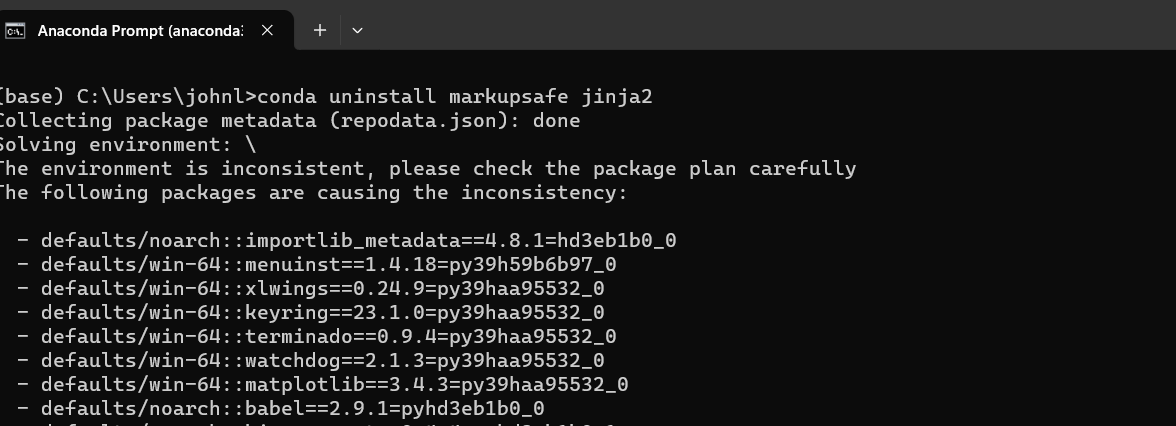

    However, I did do a lot more work and found that if I ddin't use the residuals to fit and predict the nature of the Gradient boosting algorithm removed the seasonal and trend components by being very 'either or' in the predictions. Due to the stump nature of the model. The seasonal and trend get mashed up with the reisiduals and the output is like a piecewies step function. Hence my approach to use decomposed residuals for fitting and prediction. 

    - While I used MSE as required, I also used of a variety of other performance metrics like MAE and MAPE. I found that MAPE was a more stable measure. Changing less as more estimators were added than MSE which, as I mentioned before, can be made arbitrarily small due to overfitting. 

    - I also tried to make a forecast for the NZ inflation for the third quarter in 2024 which I estimate to be 2.11. For this estimate I used all the data, both training and test to model the forecast, as this would be a real life situation - I'd have all prior data and be looking to predict only a few time steps in advance. Here I showed that my method of using seasonally decomposed data and reconstituting it can be applied to a real life situation, as one can cannibalise the seasonal and trend components of the model to predict them one step ahead. Seasonality is repeating, so is simple. Trrend a bit more difficult. With some more time I think I can make a hierarchical model that can apply more sophisticated modelling to generate trend and seasonality data many step in advance. Something like a regresson ensemble from darts. Perhaps I will leave this to a thesis. 

    - I believe I did some exceptional work like selecting 21 features from 760 engineered features, developing my own XGboost, MLP and novel decay functions, creating a model that fits very well and prediciting the Q3 CPI relatively close to a professional forecaster (Trading Econmics). I also am quite pleased with my whitening process. Which I would love to show the outputs of, but due to the aforementioned crash, I can't run any more code blocks on the fear that my whole assignment will crash. The process was the Box-Jenkins approach. First differencing the data, fitting a SARIMAX model to the residuals to find the best parameters by the BIC score of each fit, taking the best configuration to configure an ARIMA model, using those residuals and the ARIMA filter and apply it using convolution to the y variables, then running RFE with randomforest to find the most important time lags. Returning them as a data set. It takes a long time to run on 760 variables. That is for sure. And sometimes there are LU errors based on the feature. Like fourier features, due to them not being stationary. In which cases I applied another form of whitening, ZCA whitening. 
   

## [Task 3: NZ Inflation Forecasting Competition Using a Range of Algorithms (10 Marks)](#Task-3:-EXPERIMENTATION-USING-A-RANGE-OF-ALGORITHMS)

1. I performed the following:
    - [Model Comparison](#Task-3.1.-Model-Comparison)
        - I compared my best GB algorithm customisation with the performance of XGBoost, LightGBM, CatBoost and the scikit-learn implementation and found SK learn GB was best with MSE of 0.01. XGB was second best with MSE of 0.02. My own implementation of XG was not far off though, MSE 0.04! 
    
    - [Grid Search](#Task-3.2.-Grid-search)
         - I used Hyperparameter Tuning where Necessary where I focused on tuning the above algorithms. They hyper parameters can be viewed under the grid search section. Generally speaking for the OOTB models deeper trees were helpful, while with my own a more shallow tree was better. The grid search improved some algortihsm, like CatBoost to MSE 0.01, and XGB to 0.02. While others worsened due to my constrained parameter space search.  

    - [Other models](#Task-3.4-Other-models)
        - Tried some other forecasting algorithms from the darts library. Exponential smoothing, Naive forecast and regressionensemble. They performed much more poorly due to the fact that they use only the CPIyoy value to predict and because I was asking them to predict 38 periods out. Somethings they are not optimised for.

        - I thoroughly document the MSE performance over time with various tweaks and strategies and plotted them showing for the gradient boosting models on line charts under model validation: [Model Validation](#Task-3.3.-Model-Validation). Wherein you can observe the change to MSE as the model slides along the validation window. 

        - Instead of burying my MSE scores in text all over the notebook where it cannot be found and compared with other results, I instead a table at the top of the section for Task 3 to clearly display the MSE results from differnt experiments and algorithms.
      

## Task 4: AWS Technology Usage (15 Marks)

1. I used the following AWS services in my assignment (10 Marks):
    - ... <a href="#TASK-4" >AWS</a>
    - ... <a href="#TASK-4" >AWS</a>
    - ... <a href="#TASK-4" >AWS</a>

2. Below is a screenshot showing how far I have progressed in my AWS Academy set course (5 Marks):

   

## Task 5: (15 Marks)

1. List and discuss three most important things that you learned in this assignment:
    - Timeseries prediction is annoying. Date indexs are annoying. Seasonal and trend components are annoying. It's all just three times moreannoying than reugular data. I did find that using residuals only for the model and reconstituting it with trend and seasonality post fit was a very good way to get really good predictions. One must be careful here to avoid data leakage. Taking this approach means I can focus solely on residuals, which is somewhat is the vein of gradient booosting, I suppose. For the final part of the task 2 where I need to predict the next time step, this approach is on. I can use all the data at hand, so I can seasonally decompose all I want. I thought this was a novel idea again, but it turns out ThymeBoost bet me to the punch. 
    
    - A lot about loss functions and deacy and hessians. It was thanks to these that I came up with the idea to do the adaptive boost decay, which also led me to think about probabalistic decay, which led me to learn about BetaBoost which uses a beta dsitribution. I like Bayesian approaches to things because I find them more intuitive, if difficult to express to people who don't grasp probabilitiy distributions very well. Which I suppose is why I am not an educator. It was also learning about these that made me cotten onto the idea of Huber loss being good for timeseries data like the CPI with jagged outlies all over the place. And that seemed to work. I breifly entertained quantile loss as being good at this too, but it proved rubbish, being more about risk as I interpret it than prediction of actual values.
    I would like to explore the adaptive boost model further, perhaps find better ways to adapt the decay. 
    
    - Learning about graident boosting was useful. Thogh not as useful as implementing XGboost by myself and my MLPBoost. That was a lot of work, but helped. I haven't implemented a MLP from scratch in python before, only C++. My logic was that they both use trees of a kind. And trees can be stumps... Particularly MLPBoost. Although it wasn't used much it can be powerful as it can 'immitate' variability quite well. This though led me onto another few thoughs that I'd like to explore further, perhaps as part of a thesis or something. 
        1. can I create a model where each 'boost' evaluates the data on the each threshold by a series of different algorithms and picks the best one for that split, going at each round with a different select of models for each split of the threshold. Maybe KNN and MLP on one side, then tree and linear on the other and so on. I'd call this Frankenstien Boost when I get around to it.
        2. Timeseries data that is complex, like the economic ones, are difficult to predict far in advance because of shocks in the economy which do not come from the same processes that the data observed comes from. There are many processes at play, and at any given time the mix will vary. The data is only the measurement. We don't know what processes were ascendent and which not. Or if a new one unknonwn of is suddenly afoot. However, we can predict pretty well the time between events. For example in the UK a Poisson model can pretty accurately predict how many murders there will be and the time between them. This is due to the law of large numbers and the variability becoming so much, that we needn't know a lot about it to find a data space to encompase all of it. Provided we have data for it. We can to some extend predict shocks. So a good mdoel for this sort of thing would be hierarchical to some degree. Providing the likelihood of a shock and the range of probable values with their probability. Here I go sounding like a Bayesian again. A hierarchical model that could model to some degree shocks and apply them to the predictions may perform well. Or so my thinking goes. The model I fit is kind of cheating a more pure approach based on reasoning because it learns thsi variability moment by moment and cares not about the shocks. Which means it can never predict a shock. It is expecting things to be not so different from the previous step. This is because there is very little likelihood that the next big shock is going ot be captured in the features of the model. However, we don't need those feature to know there will be one. Some model like Poisson or extreme values theory models (EVT) may do better. So XG boost and its friends are good models, but they don't satisfy my itch
    

2. List and discuss three things that you did well in this assignment:
    - I definitely built a good model incorporating MLP decision tree and capable of doing xtreme gradient boosting. I think the work shows and the code is good. 
    - I am particularly stoked with the adaptive eta decay rate I created which alters the gradient descent decay of each data point, then provides a posterior distribution for the eta after the fitting has occured. This approach is entirely novel as far as I am aware, and yeilds pretty decent fits. 
    - Using seasonally decoposed data for training helped find good predictors and features. However, since many features are dropped, it was kind of pointelss in the end to do the fourier transforms. I spent a lot of time messing around with the tsfresh package, pytimetk and sf-forecast, none of which bore fruit. Meaning I had to figure this out myself. In the end this was helpful. 

3. List and discuss three most things that you think you could have done differently and imporved in this assignment:
    - This assignment was again massive. I am/was in the process of the final days of a massive software build which kept me stressed and occupied. I have an infant son. Ditto. I am organising my older son's rugby club trip to the Taupo rugby festival which makes me unable to submit on the 22nd. I am rennovating the house. I also have a wife to give attention to. And this assignment it the size of the Fat Man. It was all huge and I think again, about 50% was pointless work. In any case I had a lot of code to write and execute and debug which kept me up till past midnight every night for about a month and made me a stranger to my family. And a few bugs caused by package incompatabilities nearly led me to break down. This is partially due to me going whole hog on the MLP and Xtreme gradient boosting implementations, doing more than the required amount of work here.
    
    - I went about this using seasonally decomposed data, both test and train. I found when not doing so the predictions were a mess. However, there was lots of confusion when making the data splits and I had to retrace my steps to avoid data leakage. Due in part to my clumsy handling of dates. First time through I inadvertednly had data leakage because I processed the data as one set, bith X training and test data. Which I then had to re-do after splitting. By this time the whole assignment was pretty much written up. I had a bit of a melt down (see item 1). 
    
    - I had a bit of a crash with the pre-whitened data set. Which I deem to be OK because it wasn't the best data set, but which I am not sure if I managed to fix. The situation is that the auto_arima package uses Numpy of version <2.0, but all other packages (or most) use numpy version 2.0 or higher. So I can't do both and had to dance around the kernal to get it to work. Just as well it wasn't the better data set. This means that the notebook can't be run in a single go. You need to run it to a point. Then restart the kernal, change the packages and run it agin. If I had more time I would try figure out how to get the packages to work together. 

# TASK 1

never use a non stationary input to predict a stationary input. Like total vehilces for quarterly gdp change. 

feature selection: extract from timeseries the autocorrelation (trend and seasonality). Then look at the residual. Take candidate feature, and correlate it with the residual. If there is a high correlation (>0) the new feature is then adding value. 
whiten the target variable. then whiten the input and correlate the residuals of each?
Box jankings approahc

take a model such as ARIMA which is auto configured, then use ARIMA to whiten the timeseries. to get the residuals. auto congifurede ARIMA will look at all possible lags against the target model. 
if chosen features + chosen algo can mirror the noise, it will add to the ARIMA forcast. 

When chosen features, run model in an expanding window approach or similar. 

For forecasting always accompany metrics with visualisation. 

# TASK 2

## Task 3.3. Model Validation
[Back to top](#Index) | [To section head](#Task-3:-EXPERIMENTATION-USING-A-RANGE-OF-ALGORITHMS) | [Code](#Timeseries-Validation)

Here I validate each model. Looking at the models we can see varied behaviour. From the XGBoost's linear traininig MSE shooting up to 0.0014, to more convergent behaviour like my XG boost model and light GBM. I have snuck in one more model, the adaptive boost decay on the XG model. Purely out of curiosity. These models are all quite good, even the adaptive boost one, with an MSE of 1 for the final validation set. Not good by comparison to it's peersbut it does get to 0 around window 7. In general all the models seem to fit pretty well. 

We see that the on validation windows the models perform more reasonably in the testing MSE. XGB's last testin MSE is 0.3, the same as my XGB implementation. While the adaptive boost is well off the mark with MSE of 6. 

To round this section off we will look at a few plots of the validation. Git the XGboost plots. We see that, like the best model from task 2, the model gets better towards the last validations. partly because the model may be laerning better, but partly because the trend is plateauing coming up to 2016. A little bit of NZ economic history, Bill English was an criminally good finance minister, albeit a lacklustre PM personality. That plateau period is in and follows his tenure. While the decaline from 1988 to 2002 was during the tenure of Don Brash as head of the Reserve Bank. He implemented inflation targetting, which was ground breaking at the time. Perhaps the single most important, least spoken about and not followed act of monetary policy ever. The final crystalisation of Milton Friedman's monetarism. Prompty done away with after his tenure. Which resulted in a rise thereafter. 

Anyway, because of the implementations of the out of the box models and my custom ones, the OOTB models don't show the bands of all fits. My XGboost validations do, and these are very thin. Much smoother than the OOTB xgboost. As a comparison is is interesting to see that my implementations have missed the extreme peaks, not being as variable as the best gradient boost model which had variation enough to capture them. While the OOTB models fit remarkable perfectly. The adaptive boost is a nice contrast, because it hasa tendency to predict poorly the next time step. When coupled with XGBoost it performs much differently due to the boost trees which result in smaller gradients for eac point, so it doens't get all the needed variability from the data as it did with gradient boost. It need variance to get a wide posterior distribution for more accurate fits, but it does well regardless.

The overall excellent performance of these models is in large part due to the selected features. Consisting of CPI lagged variables, food, transportation, tradable inflation and petrol prices. These all have strong signals to CPI, explaining the white noise very well. Over all, the XGBoost model is by far the best model. Reaching MSEs of 0.0002, which are highly suspect, but which I can't reason my way out of, given the methodolgy I followed, so I will need to accept the performance.  Which is no surprise given XGBoost's reputation. 


# TASK 3

In [ ]:
metrics.mean_squared_error(y_test, reg_pred.values()), metrics.mean_squared_error(y_test, exp_pred), metrics.mean_squared_error(y_test, nf_pred)

In [ ]:
#Sklearn
 f'SKlearn GBoost MSE: {metrics.mean_squared_error(sk_GB_gridS_pred, y_tsResid):.4f}', alpha = 0.8)
#XGboost
f'XGBoost MSE: {metrics.mean_squared_error(XGB_gridS_pred, y_tsResid):.4f}', alpha = 0.8)
#CatBoost
f'CatBoost MSE; {metrics.mean_squared_error(CAT_gridS_pred, y_tsResid):.4f}', alpha = 0.8)
#LGBM
 f'LGBM MSE: {metrics.mean_squared_error(LGBM_gridS_pred, y_tsResid):.4f}', alpha = 1)
#My XGBoost
 f'My XGB MSE: {metrics.mean_squared_error(myXG_gridS_pred, y_tsResid):.4f}', alpha = 0.8)


# TASK 4